# The Lebedev / Kuzmina challenge: rotations from sequences and peak-time waves

**Lebedev, Ostrovski & Druckmann 2019** (*eNeuro*) made a deflating observation:
if neurons fire in sequence — same response shape, shifted in time — then PCA/jPCA
renders that population as a *rotation*. Rotations and sequences are two views of one
structure. No recurrent dynamics, no pattern generator, no attractor required.

**Kuzmina, Kriukov & Lebedev 2024** (*Scientific Reports*) pushed it further across 59
recordings from M1, PMd, S1, SMA, PFC and parietal cortex: rotational structure is
"consistently accounted for by a traveling-wave pattern" — a wave that travels across
the population when neurons are **sorted by their peak-firing time**. Their conclusion:
rotational dynamics and traveling waves "are typically the same phenomena," and the
rotations provide "*no insight into the underlying dynamical system*."

Two things to notice before any code:

- **The circularity.** Sorting neurons by peak time *guarantees* a wave-looking raster.
  The substantive claim is not "a wave exists" but "the peak-time order is consistent
  across conditions" — and where it isn't (their grasping datasets), rotations die.
- **No physical space anywhere.** The wave travels across a *ranking constructed from
  the data*, not across cortex. Whether that functional order coincides with an
  anatomical path is a question their data cannot ask.

This notebook demonstrates all of this in code, then does the one thing they couldn't:
put the wave in physical space.

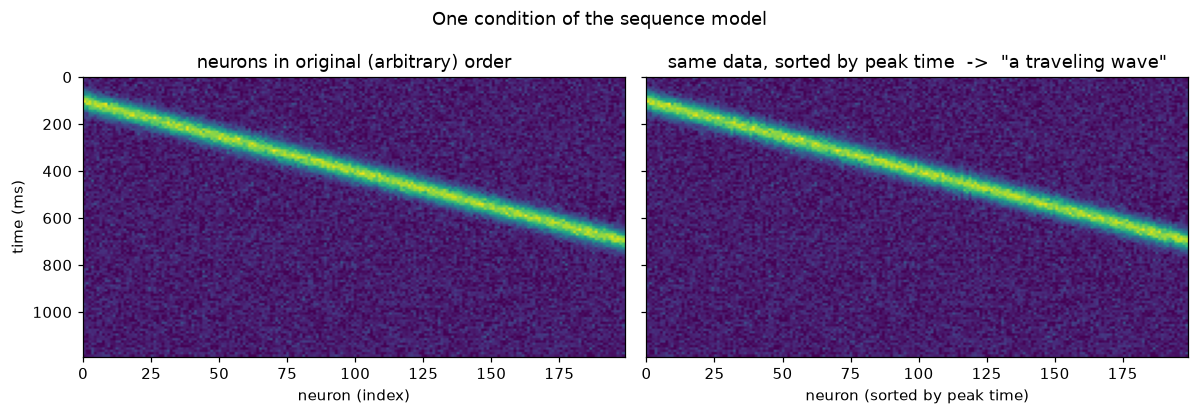

The wave in the right panel exists BY CONSTRUCTION: we sorted by peak time.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from jpca_core import *
%matplotlib inline
plt.rcParams['figure.dpi'] = 110

# --- Model A: pure sequences (Lebedev 2019) ---------------------------------
# 200 neurons; neuron j fires ONE Gaussian bump at time tau_j = 100 + 3*j ms.
# There is no dynamics here at all -- just a fixed recruitment order.
rates_seq, t_ms = simulate_sequences(n_neurons=200, spacing_ms=3.0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
peak_order = np.argsort(np.argmax(rates_seq.mean(axis=1), axis=1))
axes[0].imshow(rates_seq[:, 3].T, aspect='auto', cmap='viridis',
               extent=[0, 199, t_ms[-1], t_ms[0]])
axes[0].set_title('neurons in original (arbitrary) order')
axes[0].set_xlabel('neuron (index)'); axes[0].set_ylabel('time (ms)')
axes[1].imshow(rates_seq[peak_order][:, 3].T, aspect='auto', cmap='viridis',
               extent=[0, 199, t_ms[-1], t_ms[0]])
axes[1].set_title('same data, sorted by peak time  ->  "a traveling wave"')
axes[1].set_xlabel('neuron (sorted by peak time)')
fig.suptitle('One condition of the sequence model')
fig.tight_layout(); plt.show()
print('The wave in the right panel exists BY CONSTRUCTION: we sorted by peak time.')

Now run the **full Churchland pipeline** on this pure sequence data — same
preprocessing, same PCA, same skew-symmetric fit. If jPCA reports rotation here, then
rotation cannot be evidence of a rotational dynamical engine: this generator has no
recurrence, no oscillation, no attractor — just an order.

pure-sequence data:  whole-space rotation R^2 = 0.675
top plane: 41% of variance | 3.29 Hz | in-plane rotation R^2 = +0.19


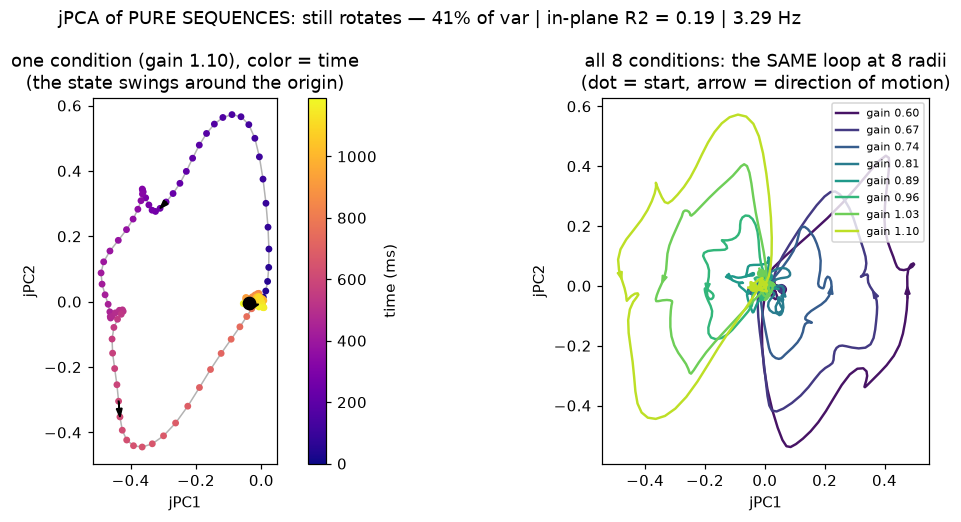

In [2]:
rates_seq_p = preprocess(rates_seq, bin_ms=10, smooth_sd_ms=20)
res_seq = jpca(rates_seq_p, n_pcs=6)
print('pure-sequence data:  whole-space rotation R^2 = %.3f' % res_seq['r2'])
coords, frac, r2p = project_planes(res_seq)[0]
print('top plane: %.0f%% of variance | %.2f Hz | in-plane rotation R^2 = %+.2f'
      % (100 * frac, res_seq['freqs_hz'][0], r2p))

C = rates_seq_p.shape[1]
gains = [0.6 + 0.5 * c / (C - 1) for c in range(C)]   # per-condition gains (see simulate_sequences)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# left panel: ONE condition, color = time (so the rotation direction is visible)
c_show = C - 1                                        # the largest loop (gain 1.10)
x = coords[0, c_show]
y = coords[1, c_show]
ax = axes[0]
ax.plot(x, y, color='0.7', linewidth=1, zorder=1)           # gray path underneath
sc = ax.scatter(x, y, c=t_ms, cmap='plasma', s=12, zorder=2)  # dots colored by time
ax.plot(x[0], y[0], 'o', color='k', markersize=8, zorder=3)   # black dot = start
for frac_i in [0.2, 0.5, 0.8]:                        # direction arrows along the way
    i = int(len(t_ms) * frac_i)
    ax.arrow(x[i], y[i], x[i + 1] - x[i], y[i + 1] - y[i], color='k',
             head_width=0.03 * np.abs(coords).max(), length_includes_head=True, zorder=3)
fig.colorbar(sc, ax=ax, label='time (ms)')
ax.set_title('one condition (gain %.2f), color = time\n(the state swings around the origin)'
             % gains[c_show])
ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')

# right panel: all 8 conditions, color = gain
ax = axes[1]
colors = plt.cm.viridis(np.linspace(0.05, 0.9, C))   # dark -> light as gain grows
for c in range(C):
    ax.plot(coords[0, c], coords[1, c], color=colors[c], linewidth=1.6,
            label='gain %.2f' % gains[c])
    ax.plot(coords[0, c, 0], coords[1, c, 0], 'o', color=colors[c], markersize=5)
    i = int(coords.shape[2] * 0.35)                  # arrow partway along the trajectory
    ax.arrow(coords[0, c, i], coords[1, c, i],
             coords[0, c, i + 1] - coords[0, c, i],
             coords[1, c, i + 1] - coords[1, c, i],
             color=colors[c], head_width=0.03 * np.abs(coords).max(),
             length_includes_head=True)
ax.set_title('all 8 conditions: the SAME loop at 8 radii\n(dot = start, arrow = direction of motion)')
ax.set_xlabel('jPC1'); ax.set_ylabel('jPC2'); ax.set_aspect('equal')
ax.legend(fontsize=7, loc='upper right')

fig.suptitle('jPCA of PURE SEQUENCES: still rotates — %.0f%% of var | in-plane R2 = %.2f | %.2f Hz'
             % (100 * frac, r2p, res_seq['freqs_hz'][0]))
fig.tight_layout(); plt.show()

The rotation appears: every condition swings around the origin in the same direction,
and the whole-space fit is strong (R² ≈ 0.68). Note the honest numbers too: the in-plane
fit is modest (R² ≈ 0.19) and the loops are open arcs, not clean circles — a wave that
passes through the population once rotates *while it lasts*, noisily. This is Lebedev's
doubt, running.

**Why it happens (one line of math):** PCA of a family of time-shifted bumps returns the
bump and its own derivative as the first two components — a quadrature pair — and a
quadrature pair plotted against itself is a circle. The "rotation" is the display format
of an order.

## The Kuzmina sweep: rotation needs a phase gradient, and collapses without it

Kuzmina et al. parameterized the wave by the spacing *b* between successive neurons'
peaks. Two degenerate limits kill the rotation — and both are instructive:

- **b = 0** — all neurons fire together (a *standing* pattern / global synchrony). The
  population state oscillates along a single direction: a line segment in state space,
  rank-1, no quadrature pair, no rotation. (Their covariance-singularity argument is the
  same fact.)
- **b → large** — peaks so spread out that neurons are effectively uncorrelated: no
  collective structure at all.

Only an intermediate spacing — a real phase gradient across the population — rotates.

peak spacing b =   0.0 ms   ->   rotation R^2 = +0.002
peak spacing b =   0.5 ms   ->   rotation R^2 = +0.458
peak spacing b =   1.0 ms   ->   rotation R^2 = +0.672
peak spacing b =   2.0 ms   ->   rotation R^2 = +0.735
peak spacing b =   3.0 ms   ->   rotation R^2 = +0.675
peak spacing b =   5.0 ms   ->   rotation R^2 = +0.558
peak spacing b =  10.0 ms   ->   rotation R^2 = +0.075
peak spacing b =  30.0 ms   ->   rotation R^2 = +0.010
peak spacing b =  80.0 ms   ->   rotation R^2 = +0.010


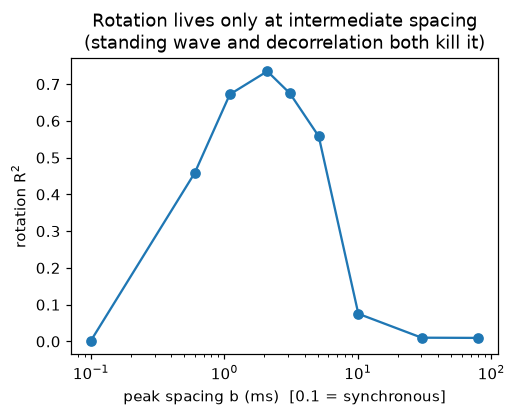

In [3]:
spacings = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 30.0, 80.0]
r2s = []
for b in spacings:
    r_b, _ = simulate_sequences(n_neurons=200, spacing_ms=b, seed=1)
    r2s.append(rotation_r2(preprocess(r_b, bin_ms=10), n_pcs=6))
    print(f'peak spacing b = {b:5.1f} ms   ->   rotation R^2 = {r2s[-1]:+.3f}')

plt.figure(figsize=(5, 3.5))
plt.semilogx(np.array(spacings) + 0.1, r2s, 'o-')
plt.xlabel('peak spacing b (ms)  [0.1 = synchronous]')
plt.ylabel('rotation R$^2$')
plt.title('Rotation lives only at intermediate spacing\n(standing wave and decorrelation both kill it)')
plt.show()

## The part they couldn't do: the wave in physical space

Kuzmina's wave travels across a *ranking*. Your question is different: does the timing
order coincide with **anatomical position** — is the functional wave a physical wave?

Here neurons sit on a 1D line and oscillate. Compare two regimes:

- **traveling wave** — phase shifts steadily across space: r(x,t) = cos(2πft − kx)
- **standing wave** — one spatial envelope oscillating in time: r(x,t) = cos(2πft)·cos(kx)

A "local electrode" (20 adjacent neurons) records each. The standing wave must NOT
produce rotation (rank-1 field: one pattern, one phase). The traveling wave must.
And the diagnostic fingerprint: in a traveling wave, each neuron's oscillation *phase*
is a linear function of its *physical position*.

**Metric note.** For a pure oscillation sampled at 1 ms, the flow-fit R² is
noise-dominated and meaningless — the derivative between adjacent bins is tiny. The
honest rotation statistics here are the *shape* of the state-space loop (ellipticity:
0 = line/standing, 1 = circle/clean quadrature) and the phase–position relationship.
Choosing the metric is part of choosing the hypothesis.

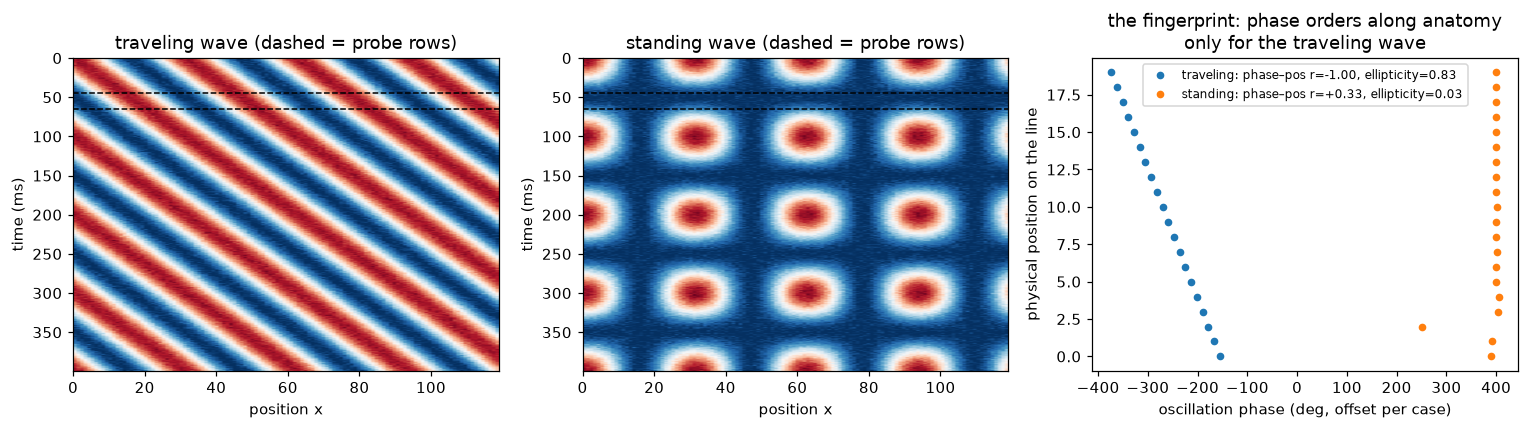

traveling | ellipticity = 0.826 | phase-position correlation = -1.000
standing  | ellipticity = 0.029 | phase-position correlation = +0.329


In [4]:
probe = slice(45, 65)   # the local electrode: 20 adjacent neurons

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, kind in enumerate(['traveling', 'standing']):
    rates_w, x, t_s = simulate_physical_wave(kind=kind, freq_hz=10.0)
    rates_probe = rates_w[probe]
    res_w = jpca(preprocess(rates_probe, bin_ms=1, subtract_condition_mean=False),
                 n_pcs=4, dt_s=0.001)
    coords, frac, r2p = project_planes(res_w)[0]
    ell = ellipticity(rates_probe)
    pos, ph = phase_vs_position(rates_probe, freq_hz=10.0, dt_s=0.001)
    ppcorr = np.corrcoef(pos, ph)[0, 1]

    ax = axes[col]
    ax.imshow(rates_w[:, 0].T, aspect='auto', cmap='RdBu_r',
              extent=[0, 119, t_s[-1]*1000, 0])
    ax.axhline(45, color='k', ls='--', lw=1); ax.axhline(65, color='k', ls='--', lw=1)
    ax.set_title(f'{kind} wave (dashed = probe rows)'); ax.set_xlabel('position x')
    ax.set_ylabel('time (ms)')

    axes[2].plot(np.degrees(ph) + 400 * col, pos, 'o', ms=4,
                 label=f'{kind}: phase–pos r={ppcorr:+.2f}, ellipticity={ell:.2f}')
axes[2].set_xlabel('oscillation phase (deg, offset per case)')
axes[2].set_ylabel('physical position on the line')
axes[2].legend(fontsize=8)
axes[2].set_title('the fingerprint: phase orders along anatomy\nonly for the traveling wave')
fig.tight_layout(); plt.show()

for kind in ['traveling', 'standing']:
    rates_w, _, _ = simulate_physical_wave(kind=kind)
    rp = rates_w[probe]
    pos, ph = phase_vs_position(rp, 10.0, 0.001)
    print(f'{kind:9s} | ellipticity = {ellipticity(rp):.3f} | '
          f'phase-position correlation = {np.corrcoef(pos, ph)[0,1]:+.3f}')

The traveling wave gives the local probe a circular state-space loop
(ellipticity → 1) and — the key figure — **phase orders linearly along physical
position**. The standing wave gives neither: ellipticity → 0 (a line segment), and phase
is flat across space. So a local jPCA rotation rules out a purely standing pattern by
itself; what it cannot tell apart, without anatomy, is *which* traveling order produced
it — the physical wave, or any other recruitment order. That is precisely the gap your
simultaneous widefield + dense-electrophysiology design closes.

## The fragility Kuzmina documented

Rotation strength is sensitive to preprocessing choices. Same sequence data, varying
only the smoothing kernel:

smoothing =    5 ms   ->   rotation R^2 = +0.163
smoothing =   10 ms   ->   rotation R^2 = +0.481
smoothing =   20 ms   ->   rotation R^2 = +0.675
smoothing =   40 ms   ->   rotation R^2 = +0.740
smoothing =   80 ms   ->   rotation R^2 = +0.443
smoothing =  150 ms   ->   rotation R^2 = +0.059


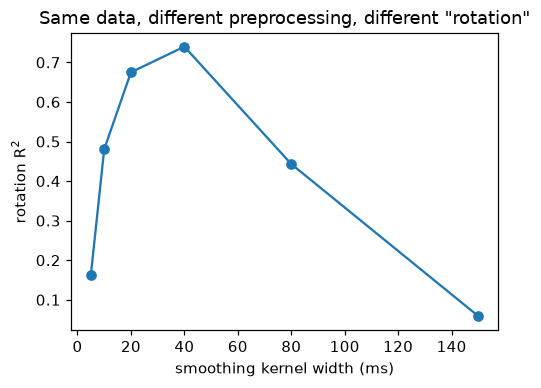

In [5]:
widths = [5, 10, 20, 40, 80, 150]
r2s = [rotation_r2(preprocess(rates_seq, bin_ms=10, smooth_sd_ms=w)) for w in widths]
for w, r in zip(widths, r2s):
    print(f'smoothing = {w:4d} ms   ->   rotation R^2 = {r:+.3f}')
plt.figure(figsize=(5, 3.5)); plt.plot(widths, r2s, 'o-')
plt.xlabel('smoothing kernel width (ms)'); plt.ylabel('rotation R$^2$')
plt.title('Same data, different preprocessing, different "rotation"')
plt.show()

## Takeaways

1. **jPCA rotation = phase-ordered structure in the population.** It is a display format,
   not a mechanism. Sequences produce it (Lebedev 2019); peak-time waves produce it
   (Kuzmina 2024); a physical traveling wave produces it. Recurrence, attractors, and
   pattern-generation machinery are *not* required.
2. **The rotation collapses for standing/synchronous patterns** (no phase gradient, no
   quadrature pair) and for decorrelated ones. Its presence tells you an order exists;
   its shape (ellipticity) tells you how clean the quadrature is.
3. **The open scientific question is spatial, not mathematical.** Everyone can find an
   ordering of neurons that makes a wave. The question nobody could ask until now:
   does that order coincide with a *physical anatomical path* — and does perturbing the
   physical wave move the latent rotation? That is the shadow test.
4. **Preprocessing is a hypothesis.** Rotation strength moves with smoothing width,
   normalization, and condition count. Report the pipeline with the result, and fix it
   before looking at the answer.